# ⚗️ Notebook 2 — Práctica
# Programación Cuántica con Qiskit

**Geronimo Martinez Núñez · Angel Nicolás Cuervo**  
Trabajo de Curso — Lenguajes de Programación

---

Este notebook contiene ejercicios progresivos. Cada ejercicio tiene:
- 📖 Contexto teórico
- 🧩 Código incompleto para completar
- ✅ Celda de verificación automática

**Prerrequisito**: haber estudiado el Notebook 1 (Teoría).

---

## Índice

1. [Setup y fundamentos de Qiskit](#setup)
2. [Ejercicio 1: Superposición con Hadamard](#ej1)
3. [Ejercicio 2: Estado de Bell (Entrelazamiento)](#ej2)
4. [Ejercicio 3 (Reto): Teleportación Cuántica](#ej3)
5. [Ejercicio 4: Reflexión — OpenQASM vs Qiskit](#ej4)
6. [Ejercicio 5: Algoritmo de Deutsch](#ej5)
7. [Ejercicio 6 (Avanzado): Algoritmo de Grover (2 qubits)](#ej6)

---
<a id='setup'></a>
## Sección 0 — Setup y Fundamentos de Qiskit

### 0.1 Instalación

Si no tienes Qiskit instalado, ejecuta en tu terminal:
```bash
pip install qiskit qiskit-aer matplotlib
```

### 0.2 Conceptos de Qiskit vs q-assembler (del Notebook 1)

| q-assembler (libro) | Qiskit | Descripción |
|---------------------|--------|-------------|
| `INITIALIZE R n` | `QuantumCircuit(n)` | Crea circuito con n qubits en $|0\rangle$ |
| `APPLY H R[i]` | `qc.h(i)` | Aplica Hadamard al qubit i |
| `APPLY CNOT R` | `qc.cx(control, target)` | Aplica CNOT |
| `MEASURE R RES` | `qc.measure(...)` | Mide y guarda en bits clásicos |
| `APPLY Rθ R[i]` | `qc.rz(theta, i)` | Phase shift |
| Subregistro SELECT | slicing en `qc` | Operaciones sobre qubits específicos |

In [7]:
# Ejecuta esta celda primero — configuración e imports
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit.quantum_info import Statevector
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Simulador estándar
sim = AerSimulator()

def run_circuit(qc, shots=2048):
    """Ejecuta un circuito y retorna el conteo de resultados."""
    result = sim.run(qc, shots=shots).result()
    return result.get_counts()

def show_statevector(qc_no_measure):
    """Muestra el vector de estado de un circuito sin medición."""
    sv = Statevector(qc_no_measure)
    print("Vector de estado:")
    n = int(np.log2(len(sv.data)))
    for i, amp in enumerate(sv.data):
        if abs(amp) > 1e-10:
            print(f"  |{format(i, f'0{n}b')}⟩: {amp:.4f}  (prob={abs(amp)**2:.4f})")
    return sv

print("✅ Setup completado. Versión de Qiskit importada correctamente.")
print(f"   Simulador: {type(sim).__name__}")

✅ Setup completado. Versión de Qiskit importada correctamente.
   Simulador: AerSimulator


---
<a id='ej1'></a>
## Ejercicio 1: Superposición con la Puerta Hadamard

### 📖 Contexto

La puerta Hadamard $H$ transforma los estados base:
$$H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}} = |+\rangle$$
$$H|1\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}} = |-\rangle$$

Aplicar $H$ a un qubit en $|0\rangle$ crea una **superposición uniforme**: 50% de probabilidad de medir 0, 50% de medir 1.

Esto corresponde al q-assembler del libro:
```
INITIALIZE R 1
APPLY H R
MEASURE R RES
```

### 🧩 Tarea

Completa el circuito para crear superposición en 1 qubit, ejecutarlo y graficar los resultados.

Circuito:
     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


TypeError: plot_bloch_multivector() got an unexpected keyword argument 'ax'

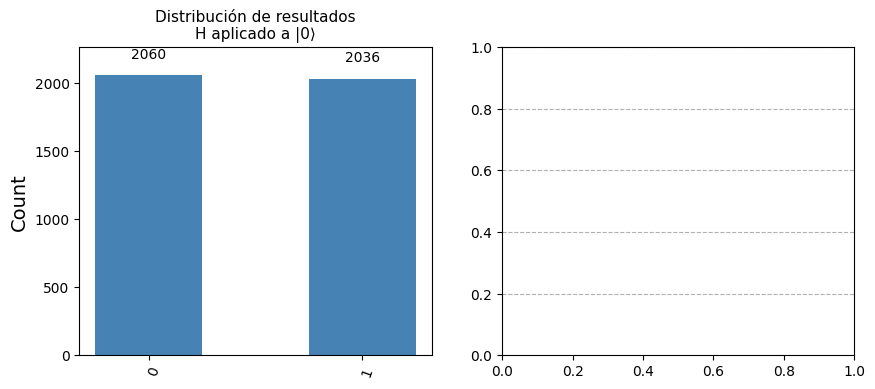

In [8]:
# === EJERCICIO 1a: Superposición de 1 qubit ===

# Crea un circuito con 1 qubit y 1 bit clásico
qc1 = QuantumCircuit(1, 1)

# TODO: Aplica la puerta Hadamard al qubit 0
qc1.h(0)

# TODO: Mide el qubit 0 y guarda en el bit clásico 0
qc1.measure(0, 0)

print("Circuito:")
print(qc1.draw(output='text'))

# Ejecutar
counts1 = run_circuit(qc1, shots=4096)

# Graficar
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

plot_histogram(counts1, ax=axes[0], color='steelblue')
axes[0].set_title('Distribución de resultados\nH aplicado a |0⟩', fontsize=11)

# Mostrar la esfera de Bloch (estado antes de medir)
qc1_sv = QuantumCircuit(1)
qc1_sv.h(0)
sv = Statevector(qc1_sv)
sv.draw('bloch', ax=axes[1])
axes[1].set_title('Estado en la esfera de Bloch\n(antes de medir)', fontsize=11)

plt.tight_layout()
plt.show()

print(f"\nResultados: {counts1}")

In [ ]:
# ✅ VERIFICACIÓN EJERCICIO 1a
assert '0' in counts1 and '1' in counts1, "❌ Ambos resultados (0 y 1) deben aparecer"
total = sum(counts1.values())
p0 = counts1.get('0', 0) / total
p1 = counts1.get('1', 0) / total
assert 0.40 < p0 < 0.60, f"❌ P(0)={p0:.2f} debe estar cerca de 0.50"
assert 0.40 < p1 < 0.60, f"❌ P(1)={p1:.2f} debe estar cerca de 0.50"
print(f"✅ Ejercicio 1a correcto: P(0)={p0:.3f}, P(1)={p1:.3f}")
print(f"   La puerta Hadamard creó superposición uniforme ✓")

✅ Ejercicio 1a correcto: P(0)=0.491, P(1)=0.509
   La puerta Hadamard creó superposición uniforme ✓


Circuito para H⊗H⊗H aplicado a |000⟩:
     ┌───┐┌─┐      
q_0: ┤ H ├┤M├──────
     ├───┤└╥┘┌─┐   
q_1: ┤ H ├─╫─┤M├───
     ├───┤ ║ └╥┘┌─┐
q_2: ┤ H ├─╫──╫─┤M├
     └───┘ ║  ║ └╥┘
c: 3/══════╩══╩══╩═
           0  1  2 


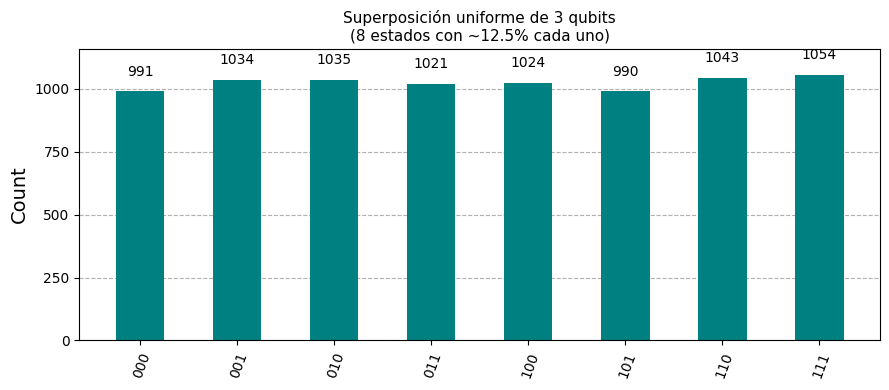


Número de estados distintos observados: 8/8


In [ ]:
# === EJERCICIO 1b: Superposición de 3 qubits (H en todos) ===
# Esto implementa el Ejemplo 7.2.4 extendido del libro

qc1b = QuantumCircuit(3, 3)

# TODO: Aplica Hadamard a los 3 qubits
# (equivale a U TENSOR H H H en q-assembler)
qc1b.h([0, 1, 2])

# TODO: Mide los 3 qubits
qc1b.measure([0, 1, 2], [0, 1, 2])

print("Circuito para H⊗H⊗H aplicado a |000⟩:")
print(qc1b.draw(output='text'))

counts1b = run_circuit(qc1b, shots=8192)

fig, ax = plt.subplots(figsize=(9, 4))
plot_histogram(counts1b, ax=ax, color='teal')
ax.set_title('Superposición uniforme de 3 qubits\n(8 estados con ~12.5% cada uno)', fontsize=11)
plt.tight_layout()
plt.show()

print(f"\nNúmero de estados distintos observados: {len(counts1b)}/8")

In [ ]:
# ✅ VERIFICACIÓN EJERCICIO 1b
assert len(counts1b) == 8, f"❌ Deben aparecer los 8 estados posibles, aparecieron {len(counts1b)}"
total = sum(counts1b.values())
probs = [v/total for v in counts1b.values()]
for p in probs:
    assert 0.08 < p < 0.17, f"❌ Probabilidad {p:.3f} muy alejada de 1/8 = 0.125"
print("✅ Ejercicio 1b correcto: superposición uniforme de 3 qubits lograda")
print("   Cada uno de los 8 estados tiene probabilidad ≈ 1/8 = 12.5% ✓")

✅ Ejercicio 1b correcto: superposición uniforme de 3 qubits lograda
   Cada uno de los 8 estados tiene probabilidad ≈ 1/8 = 12.5% ✓


---
<a id='ej2'></a>
## Ejercicio 2: Estado de Bell (Entrelazamiento Cuántico)

### 📖 Contexto

Los **estados de Bell** son los 4 estados maximalmente entrelazados de 2 qubits. El más famoso es:

$$|\Phi^+\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}$$

En este estado, los dos qubits están perfectamente correlacionados: si uno mide 0, el otro también será 0 (y vice-versa), independientemente de la distancia.

**Circuito para crear $|\Phi^+\rangle$:**
```
q₀: ─[H]─●──
          │
q₁: ─────⊕──
```

1. $H$ en qubit 0: $|00\rangle \rightarrow \frac{|0\rangle + |1\rangle}{\sqrt{2}} \otimes |0\rangle = \frac{|00\rangle + |10\rangle}{\sqrt{2}}$
2. CNOT(0→1): $\frac{|00\rangle + |10\rangle}{\sqrt{2}} \rightarrow \frac{|00\rangle + |11\rangle}{\sqrt{2}}$

### 🧩 Tarea

Construye el circuito del estado de Bell y verifica el entrelazamiento.

Circuito del Estado de Bell |Φ+⟩:
     ┌───┐     ┌─┐   
q_0: ┤ H ├──■──┤M├───
     └───┘┌─┴─┐└╥┘┌─┐
q_1: ─────┤ X ├─╫─┤M├
          └───┘ ║ └╥┘
c: 2/═══════════╩══╩═
                0  1 

Vector de estado antes de medir:
Vector de estado:
  |00⟩: 0.7071+0.0000j  (prob=0.5000)
  |11⟩: 0.7071+0.0000j  (prob=0.5000)


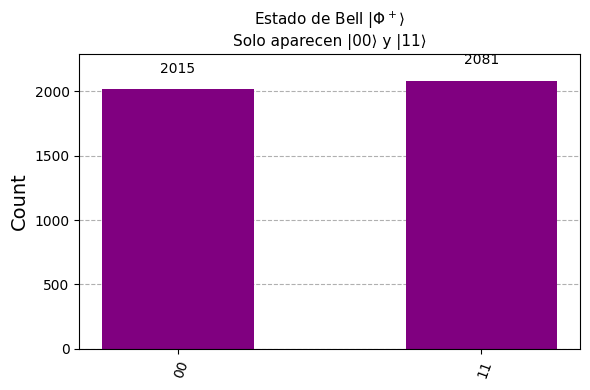

In [9]:
# === EJERCICIO 2a: Estado de Bell |Φ+⟩ ===

qc2 = QuantumCircuit(2, 2)

# TODO: Aplica Hadamard al qubit 0
qc2.h(0)

# TODO: Aplica CNOT con qubit 0 como control y qubit 1 como target
# Sintaxis: qc2.cx(control, target)
qc2.cx(0, 1)

# TODO: Mide ambos qubits
qc2.measure([0, 1], [0, 1])

print("Circuito del Estado de Bell |Φ+⟩:")
print(qc2.draw(output='text'))

# Mostrar vector de estado (sin medición)
qc2_sv = QuantumCircuit(2)
qc2_sv.h(0)
qc2_sv.cx(0, 1)
print("\nVector de estado antes de medir:")
sv2 = show_statevector(qc2_sv)

counts2 = run_circuit(qc2, shots=4096)

fig, ax = plt.subplots(figsize=(6, 4))
plot_histogram(counts2, ax=ax, color='purple')
ax.set_title('Estado de Bell $|\\Phi^+\\rangle$\nSolo aparecen |00⟩ y |11⟩', fontsize=11)
plt.tight_layout()
plt.show()

In [10]:
# ✅ VERIFICACIÓN EJERCICIO 2a
assert '00' in counts2 and '11' in counts2, "❌ Solo deben aparecer |00⟩ y |11⟩"
assert '01' not in counts2 or counts2.get('01', 0) < 50, "❌ |01⟩ no debe aparecer"
assert '10' not in counts2 or counts2.get('10', 0) < 50, "❌ |10⟩ no debe aparecer"
total = sum(counts2.values())
p00 = counts2.get('00', 0) / total
p11 = counts2.get('11', 0) / total
assert 0.45 < p00 < 0.55, f"❌ P(00)={p00:.3f} debe ser ≈ 0.5"
assert 0.45 < p11 < 0.55, f"❌ P(11)={p11:.3f} debe ser ≈ 0.5"
print("✅ Ejercicio 2a correcto: Estado de Bell |Φ+⟩ creado exitosamente")
print(f"   P(|00⟩) = {p00:.3f}, P(|11⟩) = {p11:.3f}")
print("   Solo aparecen 00 y 11 → correlación perfecta = entrelazamiento ✓")

✅ Ejercicio 2a correcto: Estado de Bell |Φ+⟩ creado exitosamente
   P(|00⟩) = 0.492, P(|11⟩) = 0.508
   Solo aparecen 00 y 11 → correlación perfecta = entrelazamiento ✓


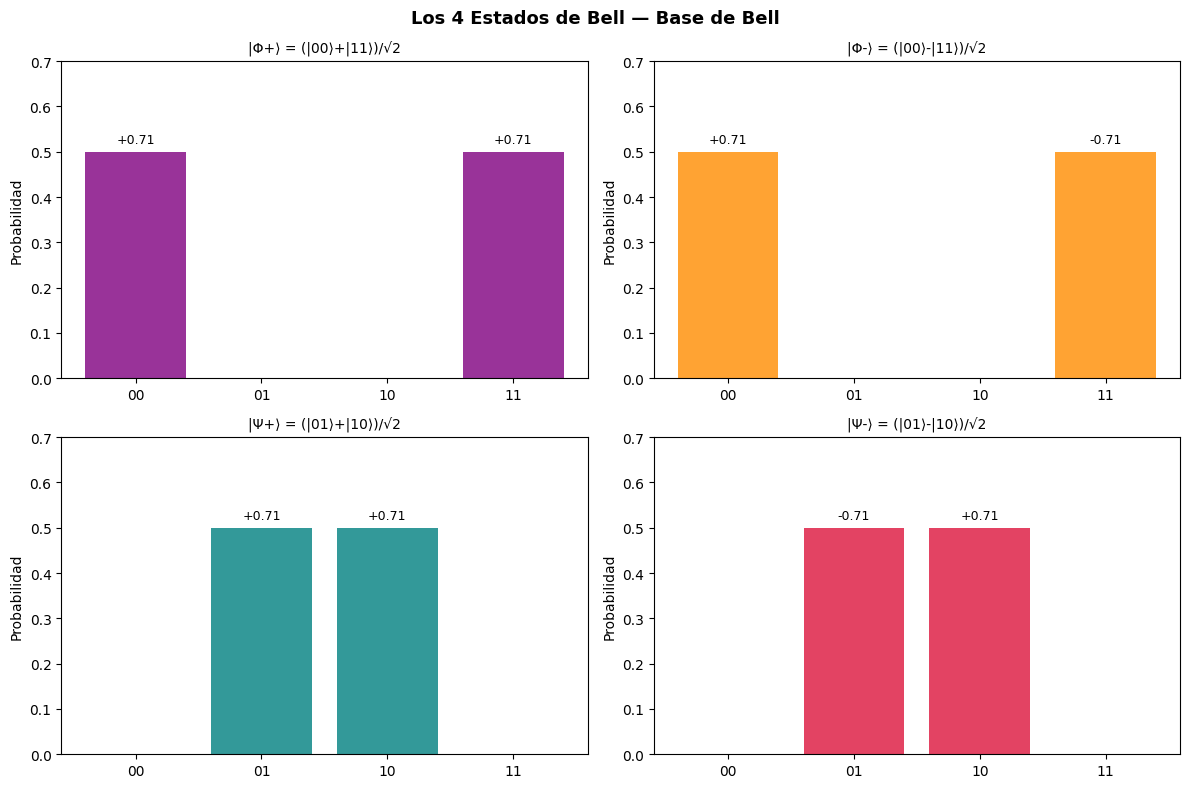

Los 4 estados de Bell forman una base ortonormal del espacio de 2 qubits.
Son los estados maximalmente entrelazados: medir un qubit determina completamente el otro.


In [11]:
# === EJERCICIO 2b: Los 4 estados de Bell ===
# Los 4 estados de Bell forman una base ortonormal del espacio de 2 qubits

bell_circuits = {}
bell_states = {
    '|Φ+⟩ = (|00⟩+|11⟩)/√2': (False, False),  # H en q0, CNOT
    '|Φ-⟩ = (|00⟩-|11⟩)/√2': (True, False),   # X en q0, luego igual
    '|Ψ+⟩ = (|01⟩+|10⟩)/√2': (False, True),   # X en q1 después
    '|Ψ-⟩ = (|01⟩-|10⟩)/√2': (True, True),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
colors = ['purple', 'darkorange', 'teal', 'crimson']

for idx, (name, (flip_q0, flip_q1)) in enumerate(bell_states.items()):
    qc_b = QuantumCircuit(2)
    if flip_q0: qc_b.x(0)
    if flip_q1: qc_b.x(1)
    qc_b.h(0)
    qc_b.cx(0, 1)
    
    sv = Statevector(qc_b)
    states = [format(i, '02b') for i in range(4)]
    amps = sv.data
    
    xs = np.arange(4)
    bars = axes[idx].bar(states, np.abs(amps)**2, color=colors[idx], alpha=0.8)
    axes[idx].set_ylim(0, 0.7)
    axes[idx].set_title(f'{name}', fontsize=10)
    axes[idx].set_ylabel('Probabilidad')
    
    for bar, amp in zip(bars, amps):
        if abs(amp) > 0.01:
            axes[idx].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                          f'{amp.real:+.2f}', ha='center', fontsize=9)

fig.suptitle('Los 4 Estados de Bell — Base de Bell', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print("Los 4 estados de Bell forman una base ortonormal del espacio de 2 qubits.")
print("Son los estados maximalmente entrelazados: medir un qubit determina completamente el otro.")

---
<a id='ej3'></a>
## Ejercicio 3 (Reto): Teleportación Cuántica

### 📖 Contexto

La **teleportación cuántica** permite transferir el estado de un qubit usando:
- 1 par de qubits entrelazados (estado de Bell compartido)
- 2 bits de comunicación clásica

**Protocolo de 3 participantes:**
- **Alice** tiene el qubit $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ que quiere teleportar
- **Alice y Bob** comparten un par de Bell $|\Phi^+\rangle$
- **Bob** recibe 2 bits clásicos de Alice y aplica correcciones

**El circuito completo:**
```
Alice
  q₀ (|ψ⟩): ─────────●──[H]──[M]──┐
  q₁ (Bell): ─[H]─●──⊕──────[M]──┼──┐
                   │              │  │
Bob                │              │  │
  q₂ (Bell): ──────⊕─────────────X──Z──→ |ψ⟩
                                  ↑  ↑
                               (bits clásicos de Alice)
```

**Pasos:**
1. Preparar el estado $|\psi\rangle$ en q₀
2. Crear par de Bell entre q₁ y q₂
3. Alice aplica CNOT(q₀→q₁) y H(q₀)
4. Alice mide q₀ y q₁
5. Bob aplica X(q₂) si medición de q₁ = 1
6. Bob aplica Z(q₂) si medición de q₀ = 1
7. El estado de q₂ es ahora $|\psi\rangle$ ✓

### 🧩 Tarea

Implementa el protocolo completo de teleportación.

In [12]:
# === EJERCICIO 3: Teleportación Cuántica ===

# Primero, definimos el estado a teleportar
# Usaremos |ψ⟩ = H|0⟩ = |+⟩ = (|0⟩+|1⟩)/√2 para poder verificar

def teleportation_circuit(prepare_state_fn):
    """
    Construye el circuito de teleportación.
    prepare_state_fn: función que aplica puertas a qc para preparar el estado en q0
    """
    qr = QuantumRegister(3, 'q')
    cr = ClassicalRegister(2, 'c')     # bits de Alice para Bob
    cr_verify = ClassicalRegister(1, 'v')  # bit de verificación en Bob
    qc = QuantumCircuit(qr, cr, cr_verify)
    
    # === PASO 1: Preparar el estado |ψ⟩ en q₀ ===
    prepare_state_fn(qc, qr)
    qc.barrier(label='|ψ⟩ listo')
    
    # === PASO 2: Crear par de Bell entre q₁ y q₂ ===
    # TODO: Aplica H a q[1]
    qc.h(qr[1])
    
    # TODO: Aplica CNOT con q[1] como control y q[2] como target
    qc.cx(qr[1], qr[2])
    
    qc.barrier(label='Bell listo')
    
    # === PASO 3: Operaciones de Alice ===
    # TODO: Aplica CNOT con q[0] como control y q[1] como target
    qc.cx(qr[0], qr[1])
    
    # TODO: Aplica H a q[0]
    qc.h(qr[0])
    
    qc.barrier(label='Alice lista')
    
    # === PASO 4: Alice mide q[0] y q[1] ===
    # TODO: Mide q[0] en c[0] y q[1] en c[1]
    qc.measure(qr[0], cr[0])
    qc.measure(qr[1], cr[1])
    
    qc.barrier(label='Medición')
    
    # === PASO 5-6: Bob aplica correcciones condicionales ===
    # Si c[1]=1: Bob aplica X a q[2]
    with qc.if_test((cr[1], 1)):
        qc.x(qr[2])
    # Si c[0]=1: Bob aplica Z a q[2]
    with qc.if_test((cr[0], 1)):
        qc.z(qr[2])
    
    # === PASO 7: Verificación — mide q[2] ===
    qc.measure(qr[2], cr_verify[0])
    
    return qc

# Estado a teleportar: |+⟩ = H|0⟩  (50% de medir 0 ó 1)
def prepare_plus(qc, qr):
    qc.h(qr[0])

qc_teleport = teleportation_circuit(prepare_plus)

print("Circuito completo de Teleportación Cuántica:")
print(qc_teleport.draw(output='text'))

Circuito completo de Teleportación Cuántica:
     ┌───┐ |ψ⟩ listo            Bell listo      ┌───┐ Alice lista ┌─┐   »
q_0: ┤ H ├─────░────────────────────░────────■──┤ H ├──────░──────┤M├───»
     └───┘     ░     ┌───┐          ░      ┌─┴─┐└───┘      ░      └╥┘┌─┐»
q_1: ──────────░─────┤ H ├──■───────░──────┤ X ├───────────░───────╫─┤M├»
               ░     └───┘┌─┴─┐     ░      └───┘           ░       ║ └╥┘»
q_2: ──────────░──────────┤ X ├─────░──────────────────────░───────╫──╫─»
               ░          └───┘     ░                      ░       ║  ║ »
c: 2/══════════════════════════════════════════════════════════════╩══╩═»
                                                                   0  1 »
v: 1/═══════════════════════════════════════════════════════════════════»
                                                                        »
«      Medición                                                        
«q_0: ────░──────────────────────────────────────────────────────────

  Resultado en el qubit de BOB tras la teleportación
  |0⟩:  2058  (50.2%)  ████████████████████
  |1⟩:  2038  (49.8%)  ███████████████████

El estado original era |+⟩ = (|0⟩+|1⟩)/√2
→ Bob debe obtener 0 y 1 con igual probabilidad ≈ 50% ✓

Esto confirma que el estado |ψ⟩ fue teleportado correctamente a Bob.
Los bits clásicos usados: 2 bits de Alice → Bob (ningún qubit fue enviado).


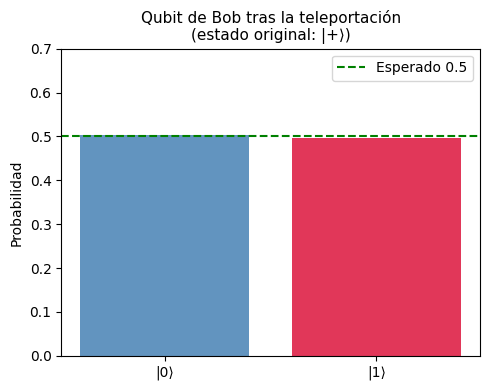

In [13]:
# Ejecutar y analizar la teleportación
counts_teleport = run_circuit(qc_teleport, shots=4096)

# Extraer solo el resultado en el qubit de Bob (bit de verificación)
# El formato es 'v c1c0' — el primer carácter es v (qubit de Bob)
bob_results = Counter()
for outcome, count in counts_teleport.items():
    # outcome tiene formato 'v cc' donde v es el qubit de Bob
    parts = outcome.split(' ')
    bob_bit = parts[0]  # primer registro = cr_verify
    bob_results[bob_bit] += count

total = sum(bob_results.values())
print("=" * 50)
print("  Resultado en el qubit de BOB tras la teleportación")
print("=" * 50)
for bit, count in sorted(bob_results.items()):
    p = count/total
    bar = '█' * int(p * 40)
    print(f"  |{bit}⟩: {count:5d}  ({p:.1%})  {bar}")

print()
print("El estado original era |+⟩ = (|0⟩+|1⟩)/√2")
print("→ Bob debe obtener 0 y 1 con igual probabilidad ≈ 50% ✓")
print()
print("Esto confirma que el estado |ψ⟩ fue teleportado correctamente a Bob.")
print("Los bits clásicos usados: 2 bits de Alice → Bob (ningún qubit fue enviado).")

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['|0⟩', '|1⟩'], [bob_results.get('0', 0)/total, bob_results.get('1', 0)/total],
       color=['steelblue', 'crimson'], alpha=0.85)
ax.axhline(0.5, color='green', linestyle='--', label='Esperado 0.5')
ax.set_ylim(0, 0.7)
ax.set_ylabel('Probabilidad')
ax.set_title('Qubit de Bob tras la teleportación\n(estado original: |+⟩)', fontsize=11)
ax.legend()
plt.tight_layout()
plt.show()

In [14]:
# ✅ VERIFICACIÓN EJERCICIO 3
p0_bob = bob_results.get('0', 0) / total
p1_bob = bob_results.get('1', 0) / total
assert 0.42 < p0_bob < 0.58, f"❌ P(0) en Bob = {p0_bob:.3f}, esperado ≈ 0.5"
assert 0.42 < p1_bob < 0.58, f"❌ P(1) en Bob = {p1_bob:.3f}, esperado ≈ 0.5"
print("✅ Ejercicio 3 correcto: ¡Teleportación exitosa!")
print(f"   Bob recibió el estado |+⟩: P(0)={p0_bob:.3f}, P(1)={p1_bob:.3f}")
print()
print("   🌟 Reflexión: El estado cuántico original (q₀ de Alice) fue destruido")
print("      al medir (no-clonación). Solo 2 bits clásicos viajaron. El estado")
print("      'apareció' en q₂ de Bob. No hay transmisión de información superlumínica")
print("      porque Bob necesita los 2 bits de Alice para saber qué correcciones aplicar.")

✅ Ejercicio 3 correcto: ¡Teleportación exitosa!
   Bob recibió el estado |+⟩: P(0)=0.502, P(1)=0.498

   🌟 Reflexión: El estado cuántico original (q₀ de Alice) fue destruido
      al medir (no-clonación). Solo 2 bits clásicos viajaron. El estado
      'apareció' en q₂ de Bob. No hay transmisión de información superlumínica
      porque Bob necesita los 2 bits de Alice para saber qué correcciones aplicar.


---
<a id='ej4'></a>
## Ejercicio 4: Reflexión — OpenQASM vs Qiskit

### 📖 Contexto

Qiskit opera en un nivel intermedio: usa Python como lenguaje huésped (paradigma QRAM) pero compila a **OpenQASM** para ejecutarse en hardware real.

**OpenQASM** (Open Quantum Assembly Language) es el equivalente real del q-assembler del libro.

### 🧩 Tarea

Compara la representación del Estado de Bell en ambas notaciones.

In [15]:
# === EJERCICIO 4: OpenQASM vs Qiskit vs q-assembler ===

# El estado de Bell en Qiskit (ya lo hiciste en el Ejercicio 2)
qc_bell = QuantumCircuit(2, 2)
qc_bell.h(0)
qc_bell.cx(0, 1)
qc_bell.measure([0, 1], [0, 1])

# Exportar a OpenQASM 3
from qiskit.qasm3 import dumps as qasm3_dumps
try:
    qasm3_code = qasm3_dumps(qc_bell)
except Exception:
    from qiskit.qasm2 import dumps as qasm2_dumps
    qasm3_code = qasm2_dumps(qc_bell)

print("=" * 60)
print("  COMPARACIÓN DE REPRESENTACIONES — Estado de Bell |Φ+⟩")
print("=" * 60)

print("\n┌─────────────────────────────────────────┐")
print("│  1. q-assembler (del libro, Sección 7.2) │")
print("└─────────────────────────────────────────┘")
print("""
  INITIALIZE R 2            // 2 qubits en |00⟩
  U TENSOR H I2             // U = H ⊗ I₂
  APPLY U R                 // H en qubit 0
  APPLY CNOT R              // CNOT(0→1)
  MEASURE R RES             // medir ambos qubits
""")

print("\n┌─────────────────────────────────────────┐")
print("│  2. OpenQASM (lenguaje circuital real)   │")
print("└─────────────────────────────────────────┘")
print(qasm3_code)

print("\n┌─────────────────────────────────────────┐")
print("│  3. Qiskit Python (SDK de nivel medio)  │")
print("└─────────────────────────────────────────┘")
print("""
  from qiskit import QuantumCircuit
  
  qc = QuantumCircuit(2, 2)  # INITIALIZE R 2
  qc.h(0)                    # APPLY H R[0]
  qc.cx(0, 1)                # APPLY CNOT R
  qc.measure([0,1],[0,1])    # MEASURE R RES
""")

print("\n┌──────────────────────────────────────────┐")
print("│  4. QCL (lenguaje imperativo Ömer, 1998) │")
print("└──────────────────────────────────────────┘")
print("""
  qureg R[2];          // registro de 2 qubits
  H(R[0]);             // Hadamard en qubit 0
  CNot(R[1], R[0]);    // CNOT(control=R[0], target=R[1])
  measure R;           // medir
""")

print("\n┌──────────────────────────────────────────┐")
print("│  5. QFC / Selinger (funcional, 2004)     │")
print("└──────────────────────────────────────────┘")
print("""
  new qbit p, q := 0   // inicializa en |00⟩
  p *= H               // Hadamard en p
  -- (CNOT en QFC se expresa como composición)
""")

  COMPARACIÓN DE REPRESENTACIONES — Estado de Bell |Φ+⟩

┌─────────────────────────────────────────┐
│  1. q-assembler (del libro, Sección 7.2) │
└─────────────────────────────────────────┘

  INITIALIZE R 2            // 2 qubits en |00⟩
  U TENSOR H I2             // U = H ⊗ I₂
  APPLY U R                 // H en qubit 0
  APPLY CNOT R              // CNOT(0→1)
  MEASURE R RES             // medir ambos qubits


┌─────────────────────────────────────────┐
│  2. OpenQASM (lenguaje circuital real)   │
└─────────────────────────────────────────┘
OPENQASM 3.0;
include "stdgates.inc";
bit[2] c;
qubit[2] q;
h q[0];
cx q[0], q[1];
c[0] = measure q[0];
c[1] = measure q[1];


┌─────────────────────────────────────────┐
│  3. Qiskit Python (SDK de nivel medio)  │
└─────────────────────────────────────────┘

  from qiskit import QuantumCircuit

  qc = QuantumCircuit(2, 2)  # INITIALIZE R 2
  qc.h(0)                    # APPLY H R[0]
  qc.cx(0, 1)                # APPLY CNOT R
  qc.measure([0,1]

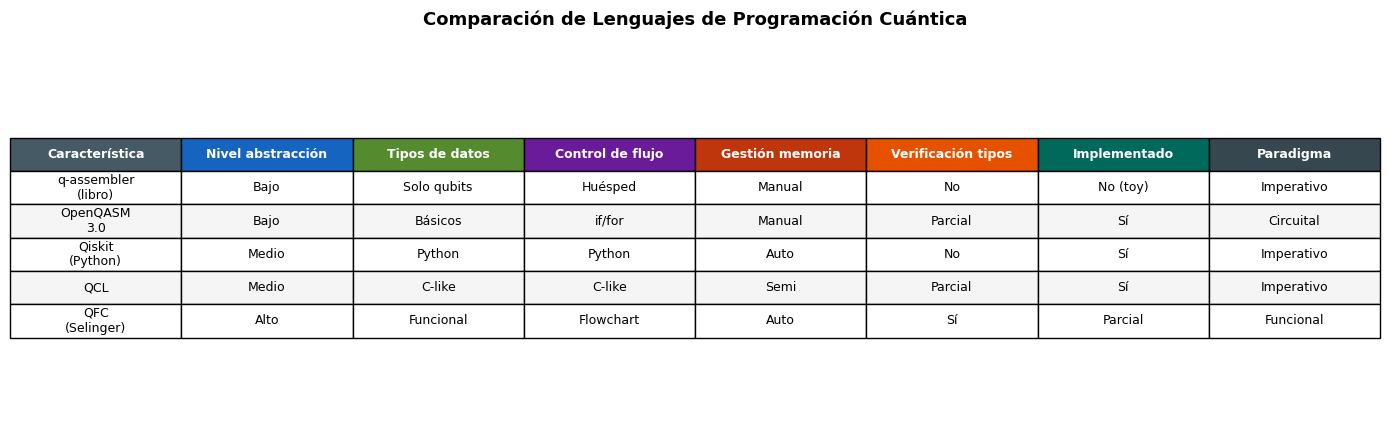

In [16]:
# Análisis comparativo: características de diseño

caracteristicas = {
    'Característica':          ['q-assembler\n(libro)', 'OpenQASM\n3.0', 'Qiskit\n(Python)', 'QCL', 'QFC\n(Selinger)'],
    'Nivel abstracción':        ['Bajo',    'Bajo',   'Medio',  'Medio',   'Alto'],
    'Tipos de datos':          ['Solo qubits', 'Básicos', 'Python', 'C-like', 'Funcional'],
    'Control de flujo':        ['Huésped', 'if/for', 'Python', 'C-like', 'Flowchart'],
    'Gestión memoria':         ['Manual',  'Manual', 'Auto',   'Semi',    'Auto'],
    'Verificación tipos':      ['No', 'Parcial', 'No', 'Parcial', 'Sí'],
    'Implementado':            ['No (toy)', 'Sí',    'Sí',     'Sí',      'Parcial'],
    'Paradigma':               ['Imperativo', 'Circuital', 'Imperativo', 'Imperativo', 'Funcional'],
}

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.axis('off')

n_rows = len(list(caracteristicas.values())[0]) + 1
n_cols = len(caracteristicas)

data = [[k] + v for k, v in caracteristicas.items()]
# Transponer
headers = [row[0] for row in data]
rows = [[row[i] for row in data] for i in range(1, n_rows)]

table = ax.table(
    cellText=rows,
    colLabels=headers,
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.8)

# Colorear encabezados
colors_header = ['#455A64', '#1565C0', '#558B2F', '#6A1B9A', '#BF360C', '#E65100', '#00695C', '#37474F']
for j, color in enumerate(colors_header[:len(headers)]):
    table[0, j].set_facecolor(color)
    table[0, j].set_text_props(color='white', fontweight='bold')

# Colorear filas alternas
for i in range(1, n_rows):
    for j in range(n_cols):
        if i % 2 == 0:
            table[i, j].set_facecolor('#F5F5F5')

ax.set_title('Comparación de Lenguajes de Programación Cuántica', 
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 🤔 Preguntas de reflexión

Responde en la siguiente celda markdown (doble clic para editar):

**Pregunta 1**: ¿Qué ventajas ofrece Qiskit (Python) sobre OpenQASM para un desarrollador?

Permite utilizar todas las herramientas, librerías y estructuras de control de Python, facilitando la integración con algoritmos clásicos y el desarrollo de software híbrido.

---

**Pregunta 2**: ¿Por qué el paradigma funcional (QFC, QML) sería más conveniente que el imperativo para lenguajes cuánticos de alto nivel? Pista: piensa en la reversibilidad y el no-clonación.

Porque el paradigma funcional se alinea de forma natural con la inmutabilidad (evitando efectos secundarios y la clonación de estados prohibida por el teorema de no-clonación) y las transformaciones puras, que se ajustan mejor a la reversibilidad intrínseca de la computación cuántica.

---

**Pregunta 3**: El libro dice que el modelo QRAM es análogo a un programador de juegos 3D usando instrucciones de GPU. ¿Cuál sería la analogía equivalente hoy en 2025 (con LLMs, TPUs, etc.)?

Sería como un desarrollador de IA que utiliza un lenguaje de alto nivel como Python para enviar modelos y cálculos pesados a una TPU, NPU o clúster de GPUs, de tal forma que el acelerador hardware maneje masivamente la lógica paralela.

---
<a id='ej5'></a>
## Ejercicio 5: Algoritmo de Deutsch

### 📖 Contexto

El algoritmo de Deutsch resuelve el siguiente problema:

Dada una función $f: \{0, 1\} \rightarrow \{0, 1\}$, determinar si es:
- **Constante**: $f(0) = f(1)$ (siempre 0 o siempre 1)
- **Balanceada**: $f(0) \neq f(1)$ (un 0 y un 1)

Un algoritmo clásico necesita **2 evaluaciones** de $f$.  
El algoritmo de Deutsch lo hace en **1 evaluación** usando superposición.

**Circuito:**
```
|0⟩ ─[H]─┤   ├─[H]─[M]
          │ Uf│
|1⟩ ─[H]─┤   ├──────
```

**Resultado**: Si el primer qubit mide **0** → $f$ es **constante**. Si mide **1** → $f$ es **balanceada**.

Este ejercicio es el **Ejercicio 7.2.6** del libro.

In [17]:
# === EJERCICIO 5: Algoritmo de Deutsch ===

def deutsch_algorithm(oracle):
    """
    Implementa el algoritmo de Deutsch.
    oracle: función que toma el QuantumCircuit y aplica la puerta Uf
    Retorna: 'constante' o 'balanceada'
    """
    qc = QuantumCircuit(2, 1)
    
    # TODO: Inicializar: qubit 0 en |0⟩, qubit 1 en |1⟩
    # Pista: |1⟩ = X|0⟩
    qc.x(1)
    
    # TODO: Aplicar Hadamard a ambos qubits
    qc.h([0, 1])
    
    # Aplicar el oráculo Uf
    oracle(qc)
    
    # TODO: Aplicar Hadamard al qubit 0
    qc.h(0)
    
    # TODO: Medir el qubit 0
    qc.measure(0, 0)
    
    # Ejecutar
    counts = run_circuit(qc, shots=1024)
    
    # El resultado más frecuente determina si f es constante o balanceada
    result_bit = max(counts, key=counts.get)
    return 'constante' if result_bit == '0' else 'balanceada', qc, counts


# === Los 4 oráculos posibles ===

def oracle_f_constante_0(qc):
    """f(x) = 0 para todo x (constante)"""
    pass  # No hace nada — Uf es la identidad

def oracle_f_constante_1(qc):
    """f(x) = 1 para todo x (constante)"""
    qc.x(1)  # Aplica X al qubit auxiliar

def oracle_f_balanceada_id(qc):
    """f(x) = x (balanceada: f(0)=0, f(1)=1)"""
    qc.cx(0, 1)  # CNOT: flipa qubit 1 si qubit 0 = 1

def oracle_f_balanceada_not(qc):
    """f(x) = NOT(x) (balanceada: f(0)=1, f(1)=0)"""
    qc.cx(0, 1)
    qc.x(1)


# Probar con los 4 oráculos
oracles = [
    (oracle_f_constante_0, 'f(x)=0', 'constante'),
    (oracle_f_constante_1, 'f(x)=1', 'constante'),
    (oracle_f_balanceada_id, 'f(x)=x', 'balanceada'),
    (oracle_f_balanceada_not, 'f(x)=NOT(x)', 'balanceada'),
]

print("=" * 60)
print("  Resultados del Algoritmo de Deutsch")
print("=" * 60)
all_correct = True
for oracle_fn, fname, expected in oracles:
    resultado, qc_d, counts_d = deutsch_algorithm(oracle_fn)
    correct = '✅' if resultado == expected else '❌'
    print(f"  {correct} {fname:15s} → detectado: {resultado:10s} (esperado: {expected})")
    if resultado != expected:
        all_correct = False

print()
print("Circuito de ejemplo (f(x)=x, balanceada):")
_, qc_example, _ = deutsch_algorithm(oracle_f_balanceada_id)
print(qc_example.draw(output='text'))

if all_correct:
    print("\n🎉 ¡Todos los oráculos detectados correctamente con 1 sola evaluación!")
    print("   En contraste, un algoritmo clásico necesitaría 2 evaluaciones de f.")

  Resultados del Algoritmo de Deutsch
  ✅ f(x)=0          → detectado: constante  (esperado: constante)
  ✅ f(x)=1          → detectado: constante  (esperado: constante)
  ✅ f(x)=x          → detectado: balanceada (esperado: balanceada)
  ✅ f(x)=NOT(x)     → detectado: balanceada (esperado: balanceada)

Circuito de ejemplo (f(x)=x, balanceada):
     ┌───┐          ┌───┐┌─┐
q_0: ┤ H ├───────■──┤ H ├┤M├
     ├───┤┌───┐┌─┴─┐└───┘└╥┘
q_1: ┤ X ├┤ H ├┤ X ├──────╫─
     └───┘└───┘└───┘      ║ 
c: 1/═════════════════════╩═
                          0 

🎉 ¡Todos los oráculos detectados correctamente con 1 sola evaluación!
   En contraste, un algoritmo clásico necesitaría 2 evaluaciones de f.


---
<a id='ej6'></a>
## Ejercicio 6 (Avanzado): Algoritmo de Grover (2 qubits)

### 📖 Contexto

El algoritmo de Grover busca un elemento marcado en una base de datos no ordenada de $N$ elementos en $O(\sqrt{N})$ evaluaciones del oráculo, contra $O(N)$ clásico.

Para $N = 4$ (2 qubits), **1 iteración** es suficiente.

**Pasos:**
1. Inicializar superposición uniforme: $H^{\otimes 2}|00\rangle$
2. Aplicar el **oráculo $O_f$**: invierte la fase del estado marcado $|\omega\rangle$
3. Aplicar el **difusor de Grover**: $2|s\rangle\langle s| - I$ donde $|s\rangle = H^{\otimes 2}|00\rangle$

### 🧩 Tarea

Implementa Grover para buscar el estado $|11\rangle$ en el espacio de 2 qubits.

In [18]:
# === EJERCICIO 6: Algoritmo de Grover (2 qubits) ===

def grover_oracle_11(qc):
    """
    Oráculo que marca el estado |11⟩:
    Aplica una fase de -1 solo al estado |11⟩.
    Implementación: CZ (controlled-Z entre q0 y q1)
    """
    # CZ invierte la fase de |11⟩: |11⟩ → -|11⟩
    qc.cz(0, 1)

def grover_diffuser(qc):
    """
    Operador de difusión de Grover: 2|s⟩⟨s| - I
    Implementación para 2 qubits:
      H⊗H · (2|00⟩⟨00| - I) · H⊗H
    """
    # H en ambos qubits
    qc.h([0, 1])
    # X en ambos qubits
    qc.x([0, 1])
    # CZ: aplica fase -1 a |11⟩ (que corresponde a |00⟩ invertido)
    qc.cz(0, 1)
    # X en ambos
    qc.x([0, 1])
    # H en ambos
    qc.h([0, 1])

# Construir el circuito de Grover
qc_grover = QuantumCircuit(2, 2)

# TODO: Paso 1 — Inicializar superposición uniforme (H en ambos qubits)
qc_grover.h([0, 1])

qc_grover.barrier(label='inicio')

# TODO: Paso 2 — Aplicar el oráculo (llama a grover_oracle_11)
grover_oracle_11(qc_grover)

qc_grover.barrier(label='oráculo')

# TODO: Paso 3 — Aplicar el difusor (llama a grover_diffuser)
grover_diffuser(qc_grover)

qc_grover.barrier(label='difusor')

# TODO: Medir ambos qubits
qc_grover.measure([0, 1], [0, 1])

print("Circuito del Algoritmo de Grover (busca |11⟩):")
print(qc_grover.draw(output='text'))

Circuito del Algoritmo de Grover (busca |11⟩):
     ┌───┐ inicio     oráculo ┌───┐┌───┐   ┌───┐┌───┐ difusor ┌─┐   
q_0: ┤ H ├───░─────■─────░────┤ H ├┤ X ├─■─┤ X ├┤ H ├────░────┤M├───
     ├───┤   ░     │     ░    ├───┤├───┤ │ ├───┤├───┤    ░    └╥┘┌─┐
q_1: ┤ H ├───░─────■─────░────┤ H ├┤ X ├─■─┤ X ├┤ H ├────░─────╫─┤M├
     └───┘   ░           ░    └───┘└───┘   └───┘└───┘    ░     ║ └╥┘
c: 2/══════════════════════════════════════════════════════════╩══╩═
                                                               0  1 


  Resultados del Algoritmo de Grover
  (buscando |11⟩ en 4 posibles estados)
  |11⟩:  4096  (100.0%)  ██████████████████████████████████████████████████ ← OBJETIVO


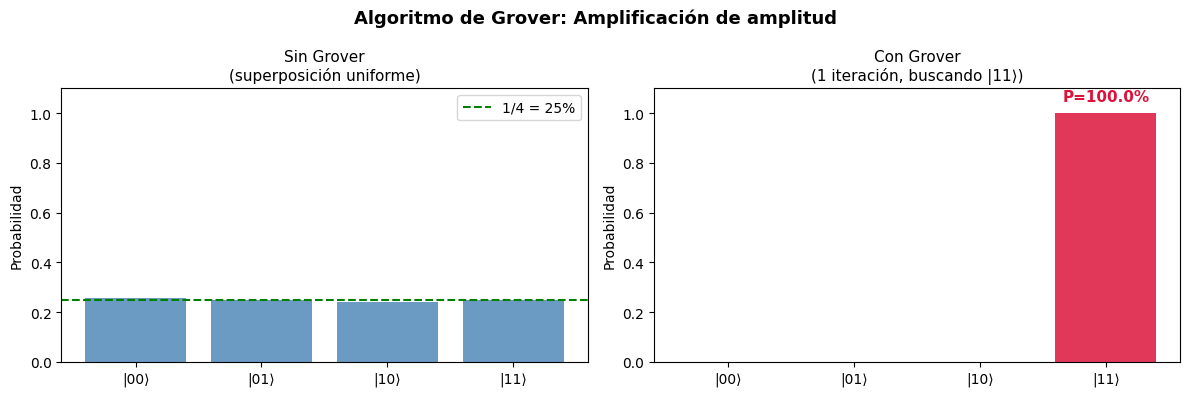

In [19]:
# Ejecutar y analizar Grover
counts_grover = run_circuit(qc_grover, shots=4096)

total = sum(counts_grover.values())
print("=" * 50)
print("  Resultados del Algoritmo de Grover")
print("  (buscando |11⟩ en 4 posibles estados)")
print("=" * 50)
for state in sorted(counts_grover.keys()):
    count = counts_grover[state]
    p = count/total
    bar = '█' * int(p * 50)
    marker = ' ← OBJETIVO' if state == '11' else ''
    print(f"  |{state}⟩: {count:5d}  ({p:.1%})  {bar}{marker}")

# Comparar: sin Grover (superposición uniforme)
qc_uniform = QuantumCircuit(2, 2)
qc_uniform.h([0, 1])
qc_uniform.measure([0, 1], [0, 1])
counts_uniform = run_circuit(qc_uniform, shots=4096)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Asegurar todos los estados
all_states = ['00', '01', '10', '11']
c_uniform = [counts_uniform.get(s, 0)/4096 for s in all_states]
c_grover = [counts_grover.get(s, 0)/4096 for s in all_states]

bar_colors = ['steelblue', 'steelblue', 'steelblue', 'crimson']

axes[0].bar([f'|{s}⟩' for s in all_states], c_uniform, color='steelblue', alpha=0.8)
axes[0].axhline(0.25, color='green', linestyle='--', label='1/4 = 25%')
axes[0].set_ylim(0, 1.1)
axes[0].set_title('Sin Grover\n(superposición uniforme)', fontsize=11)
axes[0].set_ylabel('Probabilidad')
axes[0].legend()

axes[1].bar([f'|{s}⟩' for s in all_states], c_grover, color=bar_colors, alpha=0.85)
axes[1].set_ylim(0, 1.1)
axes[1].set_title('Con Grover\n(1 iteración, buscando |11⟩)', fontsize=11)
axes[1].set_ylabel('Probabilidad')

# Anotación
idx_11 = all_states.index('11')
axes[1].annotate(f'P={c_grover[idx_11]:.1%}', 
                xy=(idx_11, c_grover[idx_11]),
                xytext=(idx_11, c_grover[idx_11]+0.05),
                ha='center', fontsize=11, color='crimson', fontweight='bold')

fig.suptitle('Algoritmo de Grover: Amplificación de amplitud', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [20]:
# ✅ VERIFICACIÓN EJERCICIO 6
p_objetivo = counts_grover.get('11', 0) / total
assert p_objetivo > 0.85, f"❌ P(|11⟩) = {p_objetivo:.3f}, Grover debe dar P > 85%"
print("✅ Ejercicio 6 correcto: ¡Algoritmo de Grover implementado!")
print(f"   P(|11⟩) = {p_objetivo:.1%} (esperado ≈ 100% para N=4, 1 iteración)")
print()
print("   📊 Speedup cuántico logrado:")
print("   - Clásico: hasta 4 evaluaciones en el peor caso (N=4)")
print("   - Grover: 1 evaluación (O(√N) = O(√4) = O(2) = 1 iteración)")
print()
print("   Para bases de datos más grandes (N=2^n), el speedup es O(√N) vs O(N).")

✅ Ejercicio 6 correcto: ¡Algoritmo de Grover implementado!
   P(|11⟩) = 100.0% (esperado ≈ 100% para N=4, 1 iteración)

   📊 Speedup cuántico logrado:
   - Clásico: hasta 4 evaluaciones en el peor caso (N=4)
   - Grover: 1 evaluación (O(√N) = O(√4) = O(2) = 1 iteración)

   Para bases de datos más grandes (N=2^n), el speedup es O(√N) vs O(N).


---

## 🏁 Resumen del Notebook 2

Completaste los siguientes ejercicios:

C:\Users\angel\AppData\Local\Temp\ipykernel_17560\3177732381.py:41: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\angel\AppData\Roaming\Python\Python312\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


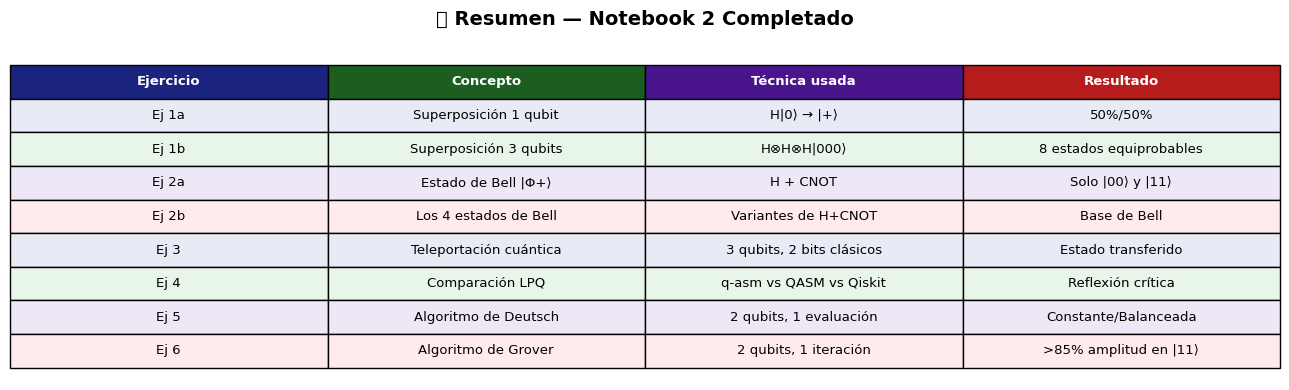


🎯 Objetivos de aprendizaje alcanzados:
   ✓ Clasificar LPQ por nivel de abstracción
   ✓ Distinguir constructos cuánticos de clásicos
   ✓ Implementar circuitos elementales en Qiskit
   ✓ Reflexionar críticamente sobre decisiones de diseño lingüístico cuántico



In [21]:
# Tabla de resumen
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

resumen = [
    ['Ej 1a', 'Superposición 1 qubit', 'H|0⟩ → |+⟩', '50%/50%'],
    ['Ej 1b', 'Superposición 3 qubits', 'H⊗H⊗H|000⟩', '8 estados equiprobables'],
    ['Ej 2a', 'Estado de Bell |Φ+⟩', 'H + CNOT', 'Solo |00⟩ y |11⟩'],
    ['Ej 2b', 'Los 4 estados de Bell', 'Variantes de H+CNOT', 'Base de Bell'],
    ['Ej 3',  'Teleportación cuántica', '3 qubits, 2 bits clásicos', 'Estado transferido'],
    ['Ej 4',  'Comparación LPQ', 'q-asm vs QASM vs Qiskit', 'Reflexión crítica'],
    ['Ej 5',  'Algoritmo de Deutsch', '2 qubits, 1 evaluación', 'Constante/Balanceada'],
    ['Ej 6',  'Algoritmo de Grover', '2 qubits, 1 iteración', '>85% amplitud en |11⟩'],
]

fig, ax = plt.subplots(figsize=(13, 4))
ax.axis('off')

headers = ['Ejercicio', 'Concepto', 'Técnica usada', 'Resultado']
table = ax.table(
    cellText=resumen,
    colLabels=headers,
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(9.5)
table.scale(1, 1.9)

header_colors = ['#1A237E', '#1B5E20', '#4A148C', '#B71C1C']
for j, color in enumerate(header_colors):
    table[0, j].set_facecolor(color)
    table[0, j].set_text_props(color='white', fontweight='bold')

row_colors = ['#E8EAF6', '#E8F5E9', '#EDE7F6', '#FFEBEE']
for i in range(1, len(resumen)+1):
    for j in range(4):
        table[i, j].set_facecolor(row_colors[(i-1) % 4])

ax.set_title('✅ Resumen — Notebook 2 Completado', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print("""
🎯 Objetivos de aprendizaje alcanzados:
   ✓ Clasificar LPQ por nivel de abstracción
   ✓ Distinguir constructos cuánticos de clásicos
   ✓ Implementar circuitos elementales en Qiskit
   ✓ Reflexionar críticamente sobre decisiones de diseño lingüístico cuántico
""")